<a href="https://colab.research.google.com/github/KrishnaKumar2002/Large-Language-Model-Practices/blob/main/Copy_of_4_Tokens_and_Bigram_LM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 4. Tokens and a Bigram Language Model

Behind the Secrets of LLMs, crash course part 2

In notebooks 0 to 3 we fitted lines, curves and handwritten digits. From now on the data is text, and the task is the one every LLM solves: given the text so far, guess the next token.

In this notebook we

1. turn text into numbers (tokenization), first with characters and then with a small BPE that we write ourselves,
2. build a language model that simply counts which character follows which (a bigram model),
3. measure how good it is with the negative log-likelihood, cross-entropy and perplexity,
4. learn the same model with gradient descent in PyTorch, using the training loop from notebook 3b,
5. generate text and control it with the temperature.

Time: about 45 minutes. A CPU is enough (in Colab: Runtime > Change runtime type > CPU).

In [1]:
import math, os, urllib.request, collections
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(42)
show_ch = lambda c: {" ": "␣", "\n": "\\n"}.get(c, c)   # make spaces/newlines visible in plots
print("torch", torch.__version__)

torch 2.11.0+cpu


## 1. Text is just a long list of characters

We use tiny Shakespeare, about 1 MB of Shakespeare plays in a single text file.

In [2]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
if not os.path.exists("input.txt"):
    urllib.request.urlretrieve(URL, "input.txt")

with open("input.txt", encoding="utf-8") as f:
    text = f.read()

print(f"{len(text):,} characters")
print(text[:300])

1,115,394 characters
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


## 2. Tokenization: from text to integers

A neural network only works with numbers. A tokenizer maps text to a list of integer IDs from a fixed vocabulary $\mathcal{V}$:

$$\text{encode}: \text{string} \rightarrow (x_1, \dots, x_n), \quad x_t \in \{0, \dots, |\mathcal{V}|-1\}$$

and `decode` turns the IDs back into text. The simplest choice is one token per character.

In [3]:
chars = sorted(set(text))
V = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}     # string -> integer
itos = {i: ch for ch, i in stoi.items()}         # integer -> string

encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[i] for i in ids)

print("vocabulary size |V| =", V)
print("vocabulary:", repr("".join(chars)))
print(encode("Hello there!"))
print(decode(encode("Hello there!")))

vocabulary size |V| = 65
vocabulary: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
[20, 43, 50, 50, 53, 1, 58, 46, 43, 56, 43, 2]
Hello there!


### Characters, words, or something in between?

| tokens are | vocabulary | sequence length | problem |
|---|---|---|---|
| characters | tiny (about 65) | very long | the model has to learn spelling, and the context fills up fast |
| words | huge (100k and more) | short | unknown words, and *run*, *runs*, *running* get unrelated IDs |
| subwords (BPE) | you choose (e.g. 50k) | medium | this is what GPT, Llama and Qwen use |

Byte-Pair Encoding (BPE) starts from single bytes and keeps merging the most frequent pair of neighbouring tokens into a new token. It only takes a few lines, so let's write it.

In [4]:
def get_pair_counts(ids):
    # count how often each adjacent pair (a, b) occurs
    return collections.Counter(zip(ids, ids[1:]))

def merge(ids, pair, new_id):
    # replace every occurrence of `pair` by the single token `new_id`
    out, i = [], 0
    while i < len(ids):
        if i < len(ids) - 1 and (ids[i], ids[i + 1]) == pair:
            out.append(new_id); i += 2
        else:
            out.append(ids[i]); i += 1
    return out

# train BPE on a slice of the text, starting from raw UTF-8 bytes (256 base tokens)
train_ids = list(text[:20000].encode("utf-8"))
ids = list(train_ids)
merges = {}                          # (a, b) -> new token id
vocab = {i: bytes([i]) for i in range(256)}
for k in range(60):                  # 60 merges -> vocabulary of 256 + 60 tokens
    pair = get_pair_counts(ids).most_common(1)[0][0]
    new_id = 256 + k
    ids = merge(ids, pair, new_id)
    merges[pair] = new_id
    vocab[new_id] = vocab[pair[0]] + vocab[pair[1]]

print("first 15 merges:", [vocab[256 + k].decode("utf-8", "replace") for k in range(15)])
print(f"{len(train_ids):,} bytes -> {len(ids):,} tokens  (compression x{len(train_ids) / len(ids):.2f})")

first 15 merges: ['e ', 'th', 't ', 's ', 'ou', ', ', 'd ', 'r ', 'in', 'an', 'en', ':\n', 'y ', '\n\n', 'er']
20,000 bytes -> 13,228 tokens  (compression x1.51)


In [5]:
def bpe_encode(s):
    ids = list(s.encode("utf-8"))
    while len(ids) >= 2:
        # apply the merge that was learned EARLIEST among the pairs present
        pair = min(get_pair_counts(ids), key=lambda p: merges.get(p, float("inf")))
        if pair not in merges:
            break
        ids = merge(ids, pair, merges[pair])
    return ids

def bpe_decode(ids):
    return b"".join(vocab[i] for i in ids).decode("utf-8", errors="replace")

s = "First Citizen: the citizens are hungry."
toks = bpe_encode(s)
print(len(s), "characters ->", len(toks), "BPE tokens")
print([bpe_decode([t]) for t in toks])
assert bpe_decode(toks) == s

39 characters -> 25 BPE tokens
['F', 'ir', 'st ', 'C', 'it', 'i', 'z', 'en', ': ', 'the ', 'c', 'it', 'i', 'z', 'en', 's ', 'ar', 'e ', 'h', 'u', 'n', 'g', 'r', 'y', '.']


**Try it:** encode a German or Hindi sentence with `bpe_encode`. Our BPE has only seen English, so how many tokens per character do you get now? Notebook 6 does the same with real LLM tokenizers.

For the rest of this notebook we stay with characters. The vocabulary is small and easy to look at.

## 3. A language model gives text a probability

With the chain rule of probability, any text can be scored one token at a time:

$$P(x_1, x_2, \dots, x_n) = \prod_{t=1}^{n} P(x_t \mid x_1, \dots, x_{t-1})$$

An LLM is a function that gives us $P(x_t \mid x_{<t})$. The bigram model makes a very strong simplification and only looks at the previous token:

$$P(x_t \mid x_{<t}) \approx P(x_t \mid x_{t-1}).$$

The easiest way to estimate this is to count how often character $b$ comes after character $a$.

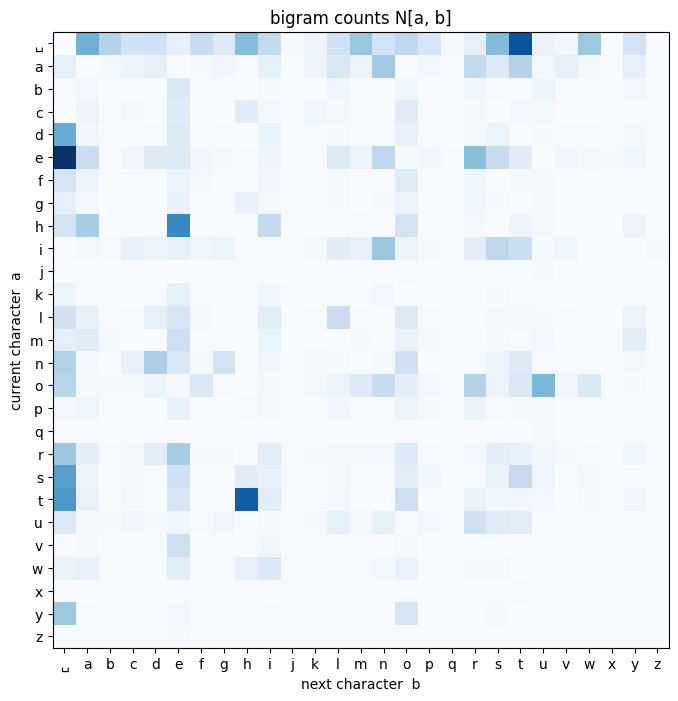

In [6]:
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]          # hold out 10% to measure generalisation

N = torch.zeros((V, V), dtype=torch.long)          # N[a, b] = how often b follows a
N.index_put_((train_data[:-1], train_data[1:]), torch.ones(n - 1, dtype=torch.long), accumulate=True)

# look at the counts for lowercase letters + space
show = [stoi[c] for c in " abcdefghijklmnopqrstuvwxyz"]
plt.figure(figsize=(8, 8))
plt.imshow(N[show][:, show], cmap="Blues")
plt.xticks(range(len(show)), [show_ch(itos[i]) for i in show])
plt.yticks(range(len(show)), [show_ch(itos[i]) for i in show])
plt.xlabel("next character  b"); plt.ylabel("current character  a")
plt.title("bigram counts N[a, b]"); plt.show()

If we divide each row by its sum, the counts become a probability distribution over the next character:

$$P(b \mid a) = \frac{N[a,b] + 1}{\sum_{b'} \left(N[a,b'] + 1\right)}$$

The $+1$ is called smoothing. It makes sure that no probability is exactly 0. Now we can sample text, one character at a time.

In [7]:
P = (N + 1).float()
P = P / P.sum(dim=1, keepdim=True)          # every row sums to 1

def sample_bigram(P, n_chars=300, start="\n"):
    g = torch.Generator().manual_seed(0)
    ix, out = stoi[start], []
    for _ in range(n_chars):
        ix = torch.multinomial(P[ix], num_samples=1, generator=g).item()
        out.append(itos[ix])
    return "".join(out)

print(sample_bigram(P))

th remofed hexpselteredoca meaman youd INAlste grecofurey h fotherere hath thig berelisseanongilost.
tho y we w ke RYORD:
Widarthofr nd; my f tsoo we w y mer aim whioervoto,
Pre co n s uzed
I s h. fo INVeprf pllie-milyompofond ssay eint odeld fleome igle inkee he t,
As toinobo y tonesthast st hayowa


It looks a bit like Shakespeare letter by letter, but not word by word. To compare models we need a number.

## 4. How good is a language model?

A good model gives a high probability to real text it has not seen before. For a held-out text $x_1, \dots, x_n$ we look at

* the **likelihood** $\prod_t P(x_t \mid x_{t-1})$. This is a tiny number, so we take logs.
* the **negative log-likelihood** per token, also called the **cross-entropy**:
$$\mathcal{L} = -\frac{1}{n}\sum_{t=1}^{n} \log P(x_t \mid x_{t-1})$$
* the **perplexity** $\text{PPL} = e^{\mathcal{L}}$. You can read it as "the model is as unsure as if it had to pick uniformly from PPL options".

A quick sanity check: a model that knows nothing picks uniformly from all $|\mathcal{V}|$ characters, so $\mathcal{L} = \log |\mathcal{V}|$ and $\text{PPL} = |\mathcal{V}|$.

In [8]:
def nll(P, d):
    return -torch.log(P[d[:-1], d[1:]]).mean().item()

uniform = math.log(V)
print(f"uniform model : loss {uniform:.3f}  perplexity {math.exp(uniform):5.1f}")
print(f"bigram (train): loss {nll(P, train_data):.3f}  perplexity {math.exp(nll(P, train_data)):5.1f}")
print(f"bigram (val)  : loss {nll(P, val_data):.3f}  perplexity {math.exp(nll(P, val_data)):5.1f}")

uniform model : loss 4.174  perplexity  65.0
bigram (train): loss 2.455  perplexity  11.6
bigram (val)  : loss 2.482  perplexity  12.0


## 5. The same model, learned with gradient descent

Counting stops working once the context is longer than one token. Neural language models learn the probabilities instead. For the bigram case the whole network is one $|\mathcal{V}| \times |\mathcal{V}|$ weight matrix $W$:

1. one-hot encode the current character: $\mathbf{e}_a \in \{0,1\}^{|\mathcal{V}|}$
2. compute the logits (raw scores) $\mathbf{z} = \mathbf{e}_a W$, which is just row $a$ of $W$
3. turn them into probabilities with the softmax: $p_b = \dfrac{e^{z_b}}{\sum_{b'} e^{z_{b'}}}$
4. the loss is the cross-entropy with the real next character $y$: $\mathcal{L} = -\log p_y$

"One-hot times a matrix picks a row" is exactly what `nn.Embedding` does. It is the first layer of every LLM.

In [9]:
W = torch.randn(V, V)
a = stoi["h"]
one_hot = F.one_hot(torch.tensor(a), V).float()
print("one-hot @ W == W[a] :", torch.allclose(one_hot @ W, W[a]))

emb = nn.Embedding(V, V)                     # a learnable lookup table
print("embedding output shape:", emb(torch.tensor([a, stoi["e"]])).shape)

one-hot @ W == W[a] : True
embedding output shape: torch.Size([2, 65])


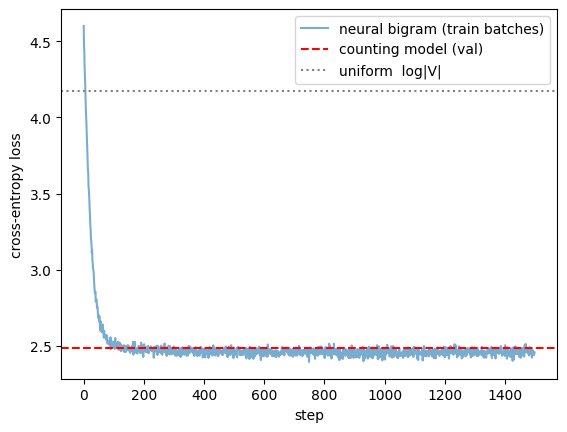

neural bigram val loss 2.490  vs counting 2.482


In [10]:
class BigramLM(nn.Module):
    def __init__(self, V):
        super().__init__()
        self.table = nn.Embedding(V, V)      # logits for the next char, one row per current char

    def forward(self, idx, targets=None):
        logits = self.table(idx)             # (B, V)
        loss = None if targets is None else F.cross_entropy(logits, targets)
        return logits, loss

model = BigramLM(V)
opt = torch.optim.Adam(model.parameters(), lr=0.05)

def batch(d, bs=4096):
    ix = torch.randint(len(d) - 1, (bs,))
    return d[ix], d[ix + 1]                  # (current char, next char)

history = []
for step in range(1500):
    x, y = batch(train_data)
    _, loss = model(x, y)        # 1. forward
    opt.zero_grad()
    loss.backward()              # 2. backward  (autograd, as in notebook 3a)
    opt.step()                   # 3. update
    history.append(loss.item())

with torch.no_grad():
    val_loss = F.cross_entropy(model.table(val_data[:-1]), val_data[1:]).item()

plt.plot(history, alpha=0.6, label="neural bigram (train batches)")
plt.axhline(nll(P, val_data), color="r", ls="--", label="counting model (val)")
plt.axhline(uniform, color="gray", ls=":", label="uniform  log|V|")
plt.xlabel("step"); plt.ylabel("cross-entropy loss"); plt.legend(); plt.show()
print(f"neural bigram val loss {val_loss:.3f}  vs counting {nll(P, val_data):.3f}")

Both end up at almost the same loss. Counting gives the maximum-likelihood answer, and gradient descent finds it too. The neural version has one big advantage: it still works for models where counting is impossible.

### Why cross-entropy is so convenient

For logits $\mathbf{z}$, softmax output $\mathbf{p}$ and one-hot target $\mathbf{y}$, the gradient is simply

$$\frac{\partial \mathcal{L}}{\partial z_b} = p_b - y_b,$$

the predicted probability minus the truth. Let's check that autograd agrees.

In [11]:
z = torch.randn(4, V, requires_grad=True)          # logits for a batch of 4
y = torch.tensor([stoi["a"], stoi["b"], stoi["c"], stoi["d"]])
F.cross_entropy(z, y).backward()                     # mean over the batch

manual = (F.softmax(z, dim=1) - F.one_hot(y, V).float()) / 4
print("autograd == softmax - one_hot :", torch.allclose(z.grad, manual.detach(), atol=1e-6))

autograd == softmax - one_hot : True


## 6. Controlling the output with the temperature

Before sampling we can divide the logits by a temperature $T$:

$$p_b = \frac{e^{z_b / T}}{\sum_{b'} e^{z_{b'}/T}}$$

* for a small $T$ the model almost always picks the most likely token (greedy and repetitive)
* $T = 1$ is the model's own distribution
* for a large $T$ the distribution gets flatter: more surprising text, and more mistakes

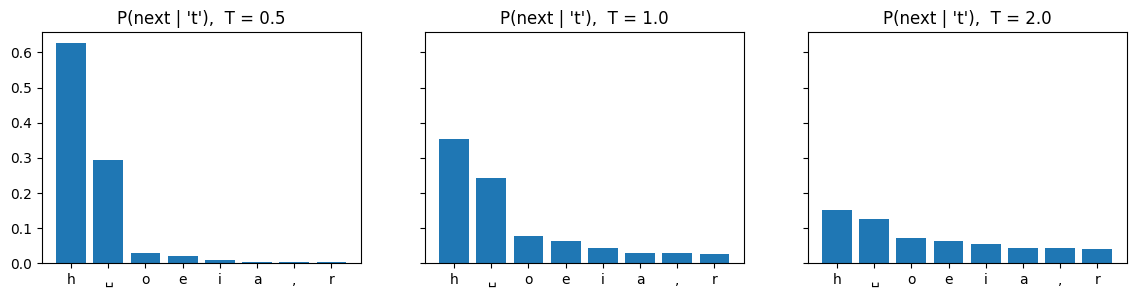

----- T = 0.3



I s there the ange be the the t hathe me t the the the thin he my ind me the thanghe he the the me withe the tor the the the the s hist t thanours me t the the me the t t t win t thin t the, there 

----- T = 1.0

Caw;

By
M:
The usil, thartie, by f ces.
Bowin'sanvif tearaicadeemotiraim. s, aroflfogaiee, hees n, grit ofoutelor d:
BUCO:
ARYeatsishisot therdvees me y! we, d deh famy bu iswhit RLLLIUCLENa, it rsh

----- T = 2.0

Caw;

qWers! me uagl,' thavieyoZo f ces.
Bowin'sacvy ceeacaic heemotirawi. xpooroalfXgaiee, je's'd, gridgofZALelordd:
Byt prn beatssasifotSt'Erdv$POH: Ra!'rehe-ghehckmmy bu izwhi'GRLLLNLOLuft, itursh



In [12]:
logits = model.table.weight[stoi["t"]].detach()      # what follows the letter 't'?
top = torch.topk(logits, 8).indices

fig, axes = plt.subplots(1, 3, figsize=(14, 3), sharey=True)
for ax, T in zip(axes, [0.5, 1.0, 2.0]):
    p = F.softmax(logits / T, dim=0)[top]
    ax.bar([show_ch(itos[i.item()]) for i in top], p)
    ax.set_title(f"P(next | 't'),  T = {T}")
plt.show()

def sample_model(T, n_chars=200):
    g = torch.Generator().manual_seed(1)
    ix, out = stoi["\n"], []
    for _ in range(n_chars):
        p = F.softmax(model.table.weight[ix].detach() / T, dim=0)
        ix = torch.multinomial(p, 1, generator=g).item()
        out.append(itos[ix])
    return "".join(out)

for T in [0.3, 1.0, 2.0]:
    print(f"----- T = {T}\n{sample_model(T)}\n")

## 7. What is still missing?

The bigram model only ever sees one previous character, so it cannot learn words, grammar or who is speaking. Its validation loss gets stuck around 2.5.

In notebook 5 (Attention and TinyGPT) every position can look at all the positions before it, using self-attention. Same data, same loss, same training loop, and much better text.

---

### Exercises

1. **Tokens per language.** Train the mini BPE with 200 merges. Compare the compression on English and on a German text you paste in.
2. **A trigram model.** Count `N[a, b, c]` in a $V \times V \times V$ tensor. Does the validation loss go down? What happens to the number of combinations you never saw?
3. **Smoothing.** Replace $+1$ by $+0.01$ and by $+100$. How do the train and validation loss change, and why?
4. **Perplexity.** Compute the perplexity of the model on `"zzzzzzzzzz"` and on `"the the the"`. Why are they so different?
5. **Temperature.** Which temperature gives the lowest validation loss on the trained logits? Why?